# Import thư viện

In [1]:
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from utils import plot_data1, plot_data2, plot_data3, plot_data_p2

# Chuẩn bị dữ liệu

In [2]:
df1 = pd.read_csv('data1.csv')
X1, y1 = df1.drop(['Group'], axis=1).values, df1['Group'].values

df2 = pd.read_csv('data2.csv')
X2, y2 = df2.drop(['Income (Million VND)'], axis=1).values, df2['Income (Million VND)'].values

# Bài tập 1 

Mục tiêu của bài tập này là giúp bạn có cái nhìn trực quan về mô hình K nearest neighbors trong
bài toán phân loại và hồi quy.

Trong bài tập có hai bộ dữ liệu *data1.csv*, *data2.csv* là thông tin khách hàng của một quán ăn.
Mỗi bộ dữ liệu gồm hai thuộc tính:
+ Age: Độ tuổi.
+ Time spent (minutes): Thời gian dành ra tại quán ăn.
Dựa vào hai thuộc tính này, mỗi bộ dữ liệu sẽ có nhãn khác nhau:
+ `data1.csv`: Đây là bộ dữ liệu có nhãn rời rạc cho bài toán phân loại. Mỗi khách hàng sẽ được
xếp vào một nhóm khác nhau để quán ăn đưa ra chính sách khuyến mãi cho từng nhóm.
+ `data2.csv`: Đây là bộ dữ liệu có nhãn liên tục cho bài toán hồi quy. Mỗi khách hàng sẽ được
khảo sát thông tin về thu nhập cá nhân.

**Nhiệm vụ** của bạn trong bài tập này là thay đổi các tham số n_neighbors, weights và điểm dữ
liệu X_test để thấy cách mô hình đưa ra quyết định trong từng trường hợp, sau đó điền kết quả thu
được vào bảng dưới đây:



|            | n_neighbors | weights  | X_test[0] | X_test[1] | label |
|------------|-------------|----------|-----------|-----------|-------|
| data1.csv  |      5      | uniform  |    20     |    20     |       |
| data1.csv  |      5      | uniform  |    30     |    30     |       |
| data1.csv  |      7      | distance |    18     |    10     |       |
| data1.csv  |      7      | distance |    30     |    45     |       |
| data2.csv  |      5      | uniform  |    15     |    20     |       |
| data2.csv  |      5      | uniform  |    30     |    50     |       |
| data2.csv  |      7      | distance |    30     |    28     |       |
| data2.csv  |      7      | distance |    30     |    45     |       |

## data1.csv

d:\bigo\bigoai\bigoai\Lecture01-KNN\Assignment\hw\utils.py:53: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


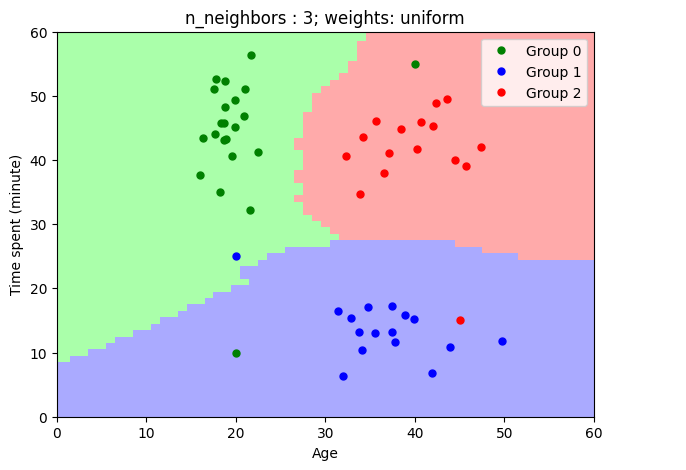

In [3]:
# Change value of the parameters

n_neighbors = 3
weights = 'uniform'

X_test = np.array([])

# Driver code - No need to change anything

clf = KNeighborsClassifier(
    n_neighbors=n_neighbors,
    weights=weights
)

clf.fit(X1, y1)
if X_test.shape[0] != 0:
    y_test = clf.predict(X_test.reshape(1, -1))[0]
    print(f'X_test belongs to Group {y_test}')
plot_data1(clf, X1, y1, X_test)

## data2.csv

d:\bigo\bigoai\bigoai\Lecture01-KNN\Assignment\hw\utils.py:97: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  fig.show()


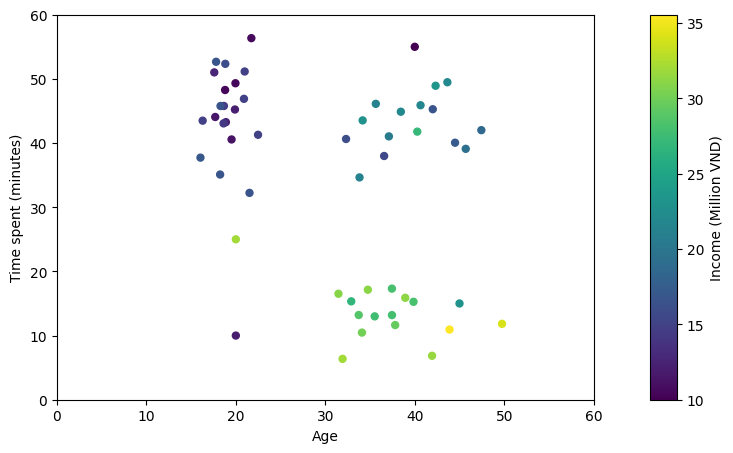

In [4]:
# Change value of the parameters

n_neighbors = 3
weights = 'distance'

X_test = np.array([])

# Driver code - No need to change anything

clf = KNeighborsRegressor(
    n_neighbors=n_neighbors,
    weights=weights
)

clf.fit(X2, y2)

if X_test.shape[0] != 0:
    y_test = clf.predict(X_test.reshape(1, -1))[0]
    print(f'Predicted value of X_test is {round(y_test, 2)}')
plot_data2(clf, X2, y2, X_test)

# Bài tập 2 

Mục tiêu của bài tập này là giúp bạn hiểu sâu hơn về mô hình `K nearest neighbors` thông qua việc
sử dụng ý tưởng của `K nearest neighbors` để phát hiện dữ liệu ngoại lai (outliers detection).

Điểm dữ liệu ngoại lai là điểm dữ liệu nằm cách xa bất thường với các điểm dữ liệu lân cận nó.

Điểm dữ liệu ngoại lai có thể xuất hiện do việc khảo sát, thống kê dữ liệu có sai sót hoặc điểm dữ
liệu này là một trường hợp ngoại lệ thường ít xảy ra. Việc sử dụng các điểm dữ liệu này trong quá
trình huấn luyện mô hình có thể đưa ra kết quả thiên vị về các điểm dữ liệu đó. Do vậy trong một
vài trường hợp ta muốn loại bỏ các điểm dữ liệu ngoại lai trước khi huấn luyện mô hình.

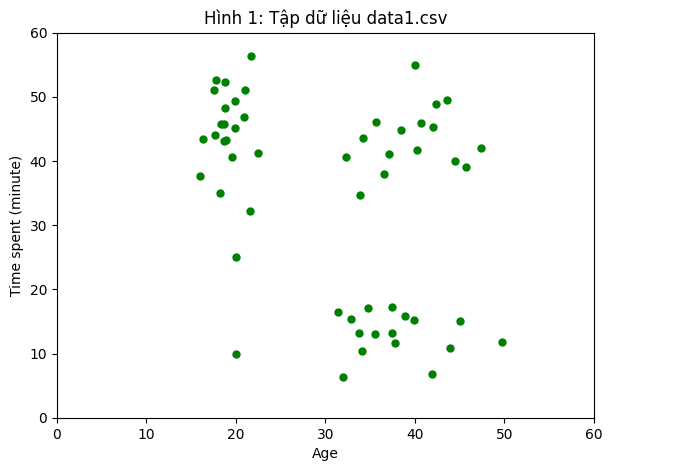

In [5]:
plot_data_p2(df1)

Quan sát các điểm dữ liệu trong `data1.csv` bạn nghĩ đâu là các điểm dữ liệu ngoại lai?  
Ý tưởng của thuật toán phát hiện điểm dữ liệu ngoại lai như sau:
1. Với mỗi điểm dữ liệu $i$ ta tính tổng khoảng cách giữa điểm dữ liệu đó với $K$ điểm dữ liệu gần
nhất, gọi giá trị này là $d_i$.
2. $M$ điểm dữ liệu ngoại lai cần loại bỏ là $M$ điểm dữ liệu có giá trị $d_i$ lớn nhất.

Bạn hãy hoàn thiện hàm `predict` trong class `OutliersDectector` theo ý tưởng trên, sau đó sử dụng
để phát hiện các điểm dữ liệu ngoại lai trong `data1.csv`.

Ta nhận thấy rằng thuật toán phát hiện dữ liệu ngoại lai này không có sử dụng nhãn dữ liệu trong
quá trình huấn luyện nên được gọi là thuật toán học không giám sát (unsupervised learning).

In [6]:
class OutliersDetector:
    def __init__(self, K: int) -> None:
        """
        Input: K - number of nearest neighbors
        """
        self.K = K

    def __distance(self, a : np.ndarray, b : np.ndarray) -> np.ndarray:
        return np.linalg.norm(a-b)

    def fit(self, X : np.ndarray) -> None:
        """
        Input: X (ndarray) - datapoints
        """
        self.X_train = X

    def predict(self, M : int) -> list[int]:
        """
        Input: M - Number of outliers
        Output: result(array) - Indexes of outliers from X_train 
        """
        
        # *** START CODE HERE *** 
        result = []
        raise NotImplementedError
        return result
        # *** END CODE HERE ***

In [8]:
# Run this cell to test your result

K = 5; M = 5
od = OutliersDetector(K)
od.fit(X1)
idxes = od.predict(M)

assert set(idxes) == {27, 3, 23, 0, 21}
print("Passed!")
plot_data3(X1, idxes)

In [ ]:
# Run this cell to test your result

K = 7; M = 10
od = OutliersDetector(K)
od.fit(X1)
idxes = od.predict(M)

assert set(idxes) == {27, 3, 23, 0, 21, 39, 14, 49, 5, 48}
print("Passed!")
plot_data3(X1, idxes)